# Julia notebook to compute the symbolic quadratures for the solution of the robust diagnostic PG problem
twnh 

Aug '26.  

This notebook reads the output from `BuoyancyEquationSolution.ipynb` and `FrictionalGeostrophicEquationSolution.ipynb`, namely the Green's functions $G_{\mathfrak{u}}$ and $G_b$ and computes integrals using them. It then writes out the following expression for later use.

\begin{align}
G_{ \mathfrak{u}, b} (z; \xi') & = 
\int_{-H}^{0} G_{ \mathfrak{u}} (z; \xi) \, \int_{\xi}^{0}  G_b(z'; \xi') \; dz'  \; d \xi .
\end{align}

See `SymbolicsTesting.jl` to test this result against numerical quadrature.

The notebook makes a plot of this $G_{ \mathfrak{u}, b} (z; \xi')$ function.

In [1]:
using SymPy
using Symbolics
using JLD2

In [2]:
# Geometry symbolic parameters:
z, ξ   = symbols("z ξ",   real=true, negative=true) # Vertical coordinate and source location (both in [-H,0])
x, y   = symbols("x y",   real=true)                # Horizontal coordinates
H      = symbols("H",   real=true, positive=true)   # Domain depth

ψ      = symbols("ψ",     real=true, positive=true) 
φ      = symbols("φ", imaginary=true)

κ      = symbols("κ",     real=true, positive=true)  # Diffusivity parameter
ν      = symbols("ν",     real=true, positive=true)  # Viscosity parameters

# Dictionary for parsing strings.
locals = Dict(
    "x" => x,
    "y" => y,
    "z" => z,
    "ξ" => ξ,
    "κ" => κ,
    "ν" => ν,
    "φ" => φ,
    "ψ" => ψ,
    "H" => H
    )

# Parse expressions using the canonical symbols.
Guv_str = read("sympy_Guv_expression.txt", String)
Guv = sympy.sympify(Guv_str, locals=locals)
println("Guv expression loaded from file:")
display(Guv)
println()

Gb_str  = read("sympy_Gb_expression.txt", String)
Gb  = sympy.sympify(Gb_str,  locals=locals)
println("Gb expression loaded from file:")
display(Gb)
println()

Guv expression loaded from file:

Gb expression loaded from file:



⎧⎛ 2⋅ξ⋅φ    2⋅φ⋅(H + z)    2⋅φ⋅(H + z + ξ)    ⎞  -φ⋅(z + ξ)           
⎪⎝ℯ      - ℯ            - ℯ                + 1⎠⋅ℯ                     
⎪──────────────────────────────────────────────────────────  for z ≤ ξ
⎪                          ⎛ 2⋅H⋅φ    ⎞                               
⎪                    2⋅ν⋅φ⋅⎝ℯ      + 1⎠                               
⎨                                                                     
⎪⎛ 2⋅z⋅φ    2⋅φ⋅(H + ξ)    2⋅φ⋅(H + z + ξ)    ⎞  -φ⋅(z + ξ)           
⎪⎝ℯ      - ℯ            - ℯ                + 1⎠⋅ℯ                     
⎪──────────────────────────────────────────────────────────  for z ≥ ξ
⎪                          ⎛ 2⋅H⋅φ    ⎞                               
⎩                    2⋅ν⋅φ⋅⎝ℯ      + 1⎠                               

⎧⎛     -2⋅ξ⋅ψ⎞ ⎛ 2⋅H⋅ψ    -2⋅z⋅ψ⎞  ψ⋅(z + ξ)           
⎪⎝1 - ℯ      ⎠⋅⎝ℯ      + ℯ      ⎠⋅ℯ                    
⎪───────────────────────────────────────────  for z ≤ ξ
⎪                  ⎛ 2⋅H⋅ψ    ⎞                        
⎪            2⋅κ⋅ψ⋅⎝ℯ      + 1⎠                        
⎨                                                      
⎪⎛     -2⋅z⋅ψ⎞ ⎛ 2⋅H⋅ψ    -2⋅ξ⋅ψ⎞  ψ⋅(z + ξ)           
⎪⎝1 - ℯ      ⎠⋅⎝ℯ      + ℯ      ⎠⋅ℯ                    
⎪───────────────────────────────────────────  for z ≥ ξ
⎪                  ⎛ 2⋅H⋅ψ    ⎞                        
⎩            2⋅κ⋅ψ⋅⎝ℯ      + 1⎠                        

In [3]:
@time begin
    zp = symbols("zp",     real=true, positive=true)
    ξp = symbols("ξp",     real=true, positive=true)
    tmp_Gb = sympy.expand(Gb.subs(Dict(z => zp, ξ => ξp)))
    tmp = sympy.factor(sympy.integrate(tmp_Gb, (zp, ξ, 0)))
end
println("1.1 Symbolic computation of the integral of Gb completed.")
display(tmp)

  0.449323 seconds (515.20 k allocations: 25.194 MiB, 2.51% gc time, 25.18% compilation time)
1.1 Symbolic computation of the integral of Gb completed.


                                2              
 ⎛ 2⋅H⋅ψ  2⋅ξp⋅ψ    ⎞ ⎛ ξ⋅ψ    ⎞   -ξ⋅ψ  -ξp⋅ψ 
-⎝ℯ     ⋅ℯ       + 1⎠⋅⎝ℯ    - 1⎠ ⋅ℯ    ⋅ℯ      
───────────────────────────────────────────────
                   2 ⎛ 2⋅H⋅ψ    ⎞              
              2⋅κ⋅ψ ⋅⎝ℯ      + 1⎠              

In [ ]:
@time begin
    tmp2 = sympy.expand(Guv * tmp)
    tmp3 = sympy.integrate(tmp2, (ξ, -H, 0))
    tmp3 = tmp3.args[1].args[1]
    max_obj = sympy.Max(-H, z)
    tmp4 = tmp3.subs(max_obj,z)
    tmp5 = sympy.factor(tmp4)
    # tmp6 = sympy.simplify(tmp5)
    tmp6 = tmp5     # No simplification
end

println("1.2 Symbolic computation of the integral of G_u and Gb completed.")
display(tmp6)

 97.423106 seconds (168.25 k allocations: 3.561 MiB, 0.01% compilation time)
1.2 Symbolic computation of the integral of G_u and Gb completed.


⎛ 2⋅ψ⋅(H + ξp)    ⎞ ⎛ 2 ⎛ H⋅ψ + z⋅φ    2⋅H⋅φ + H⋅ψ + z⋅φ⎞  2⋅z⋅ψ    2 ⎛ H⋅ψ +  ↪
⎝ℯ             + 1⎠⋅⎝φ ⋅⎝ℯ          + ℯ                 ⎠⋅ℯ      + φ ⋅⎝ℯ       ↪
────────────────────────────────────────────────────────────────────────────── ↪
                                                                               ↪
                                                                               ↪

↪ z⋅φ    2⋅H⋅φ + H⋅ψ + z⋅φ⎞   ⎛   2  H⋅φ      2  H⋅(φ + ψ)    2  H⋅(φ + 2⋅ψ)   ↪
↪     + ℯ                 ⎠ + ⎝- φ ⋅ℯ    + 2⋅φ ⋅ℯ          - φ ⋅ℯ            - ↪
↪ ──────────────────────────────────────────────────────────────────────────── ↪
↪                                                                              ↪
↪                                                                              ↪

↪   2  φ⋅(H + 2⋅z)      2  H⋅ψ + z⋅φ      2  H⋅φ + H⋅ψ + 2⋅z⋅φ    2  H⋅φ + 2⋅H ↪
↪  φ ⋅ℯ            - 2⋅φ ⋅ℯ          + 2⋅φ ⋅ℯ                  - φ ⋅ℯ          ↪
↪ ────────────────────────

In [5]:
@time symbolics_expr = sympy_to_symbolics(tmp6, [])
display(symbolics_expr)

@save "symexpr.jld2" symbolics_expr
println("1.3 Expression converted to Symbolics and saved to file: symexpr.jld2")

(exp(-H*ψ - z*φ - z*ψ - ξp*ψ)*(1 + exp(2(H + ξp)*ψ))*((exp(2H*φ + H*ψ + z*φ) + exp(H*ψ + z*φ))*(φ^2) + exp(z*ψ)*(-exp(H*φ)*(φ^2) - exp(H*(φ + 2ψ))*(φ^2) - exp((H + 2z)*φ)*(φ^2) - exp(H*φ + 2H*ψ + 2z*φ)*(φ^2) + 2exp(H*φ + H*ψ + 2z*φ)*(φ^2) - 2exp(H*ψ + z*φ)*(φ^2) + 2exp(H*(φ + ψ))*(φ^2) - 2exp(2H*φ + H*ψ + z*φ)*(φ^2) - 2exp(H*(φ + ψ))*(ψ^2) + 2exp(2H*φ + H*ψ + z*φ)*(ψ^2) + 2exp(H*ψ + z*φ)*(ψ^2) - 2exp(H*φ + H*ψ + 2z*φ)*(ψ^2)) + (exp(2H*φ + H*ψ + z*φ) + exp(H*ψ + z*φ))*exp(2z*ψ)*(φ^2))) / (2(1 + exp(2H*φ))*(1 + exp(2H*ψ))*κ*ν*(φ + ψ)*(φ - ψ)*(φ^2)*(ψ^2))

  3.854598 seconds (23.19 M allocations: 1.177 GiB, 6.89% gc time, 62.55% compilation time: 67% of which was recompilation)
1.3 Expression converted to Symbolics and saved to file: symexpr.jld2


In [6]:
# Make Symbolics.jl function
vars = collect(Symbolics.get_variables(symbolics_expr))
f_expr = build_function(symbolics_expr, vars; expression = Val(false))
f2 = eval(f_expr)
Guvb(H, z, ξp, φ, ψ, κ, ν) = f2([H, φ, ψ, z, ξp, κ, ν])        # Order of variables must match `vars`


# Test function call (see SymbolicsTesting.jl)
# Example values
Hval  = 1.0
zval  = -0.6
ξpval = -0.6
φval  = 0.05 * sqrt(im)
ψval  = 0.05
νval  = 1.0
κval  = 1.0

sym_val = Guvb(Hval, zval, ξpval,  φval, ψval, κval, νval)
println("Sample value of Guvb: ",sym_val, " should be: 0.0???? - ????-5im")

Sample value of Guvb: 0.03623190238612358 - 2.9994194087529825e-5im should be: 0.0???? - ????-5im


#### Make plots

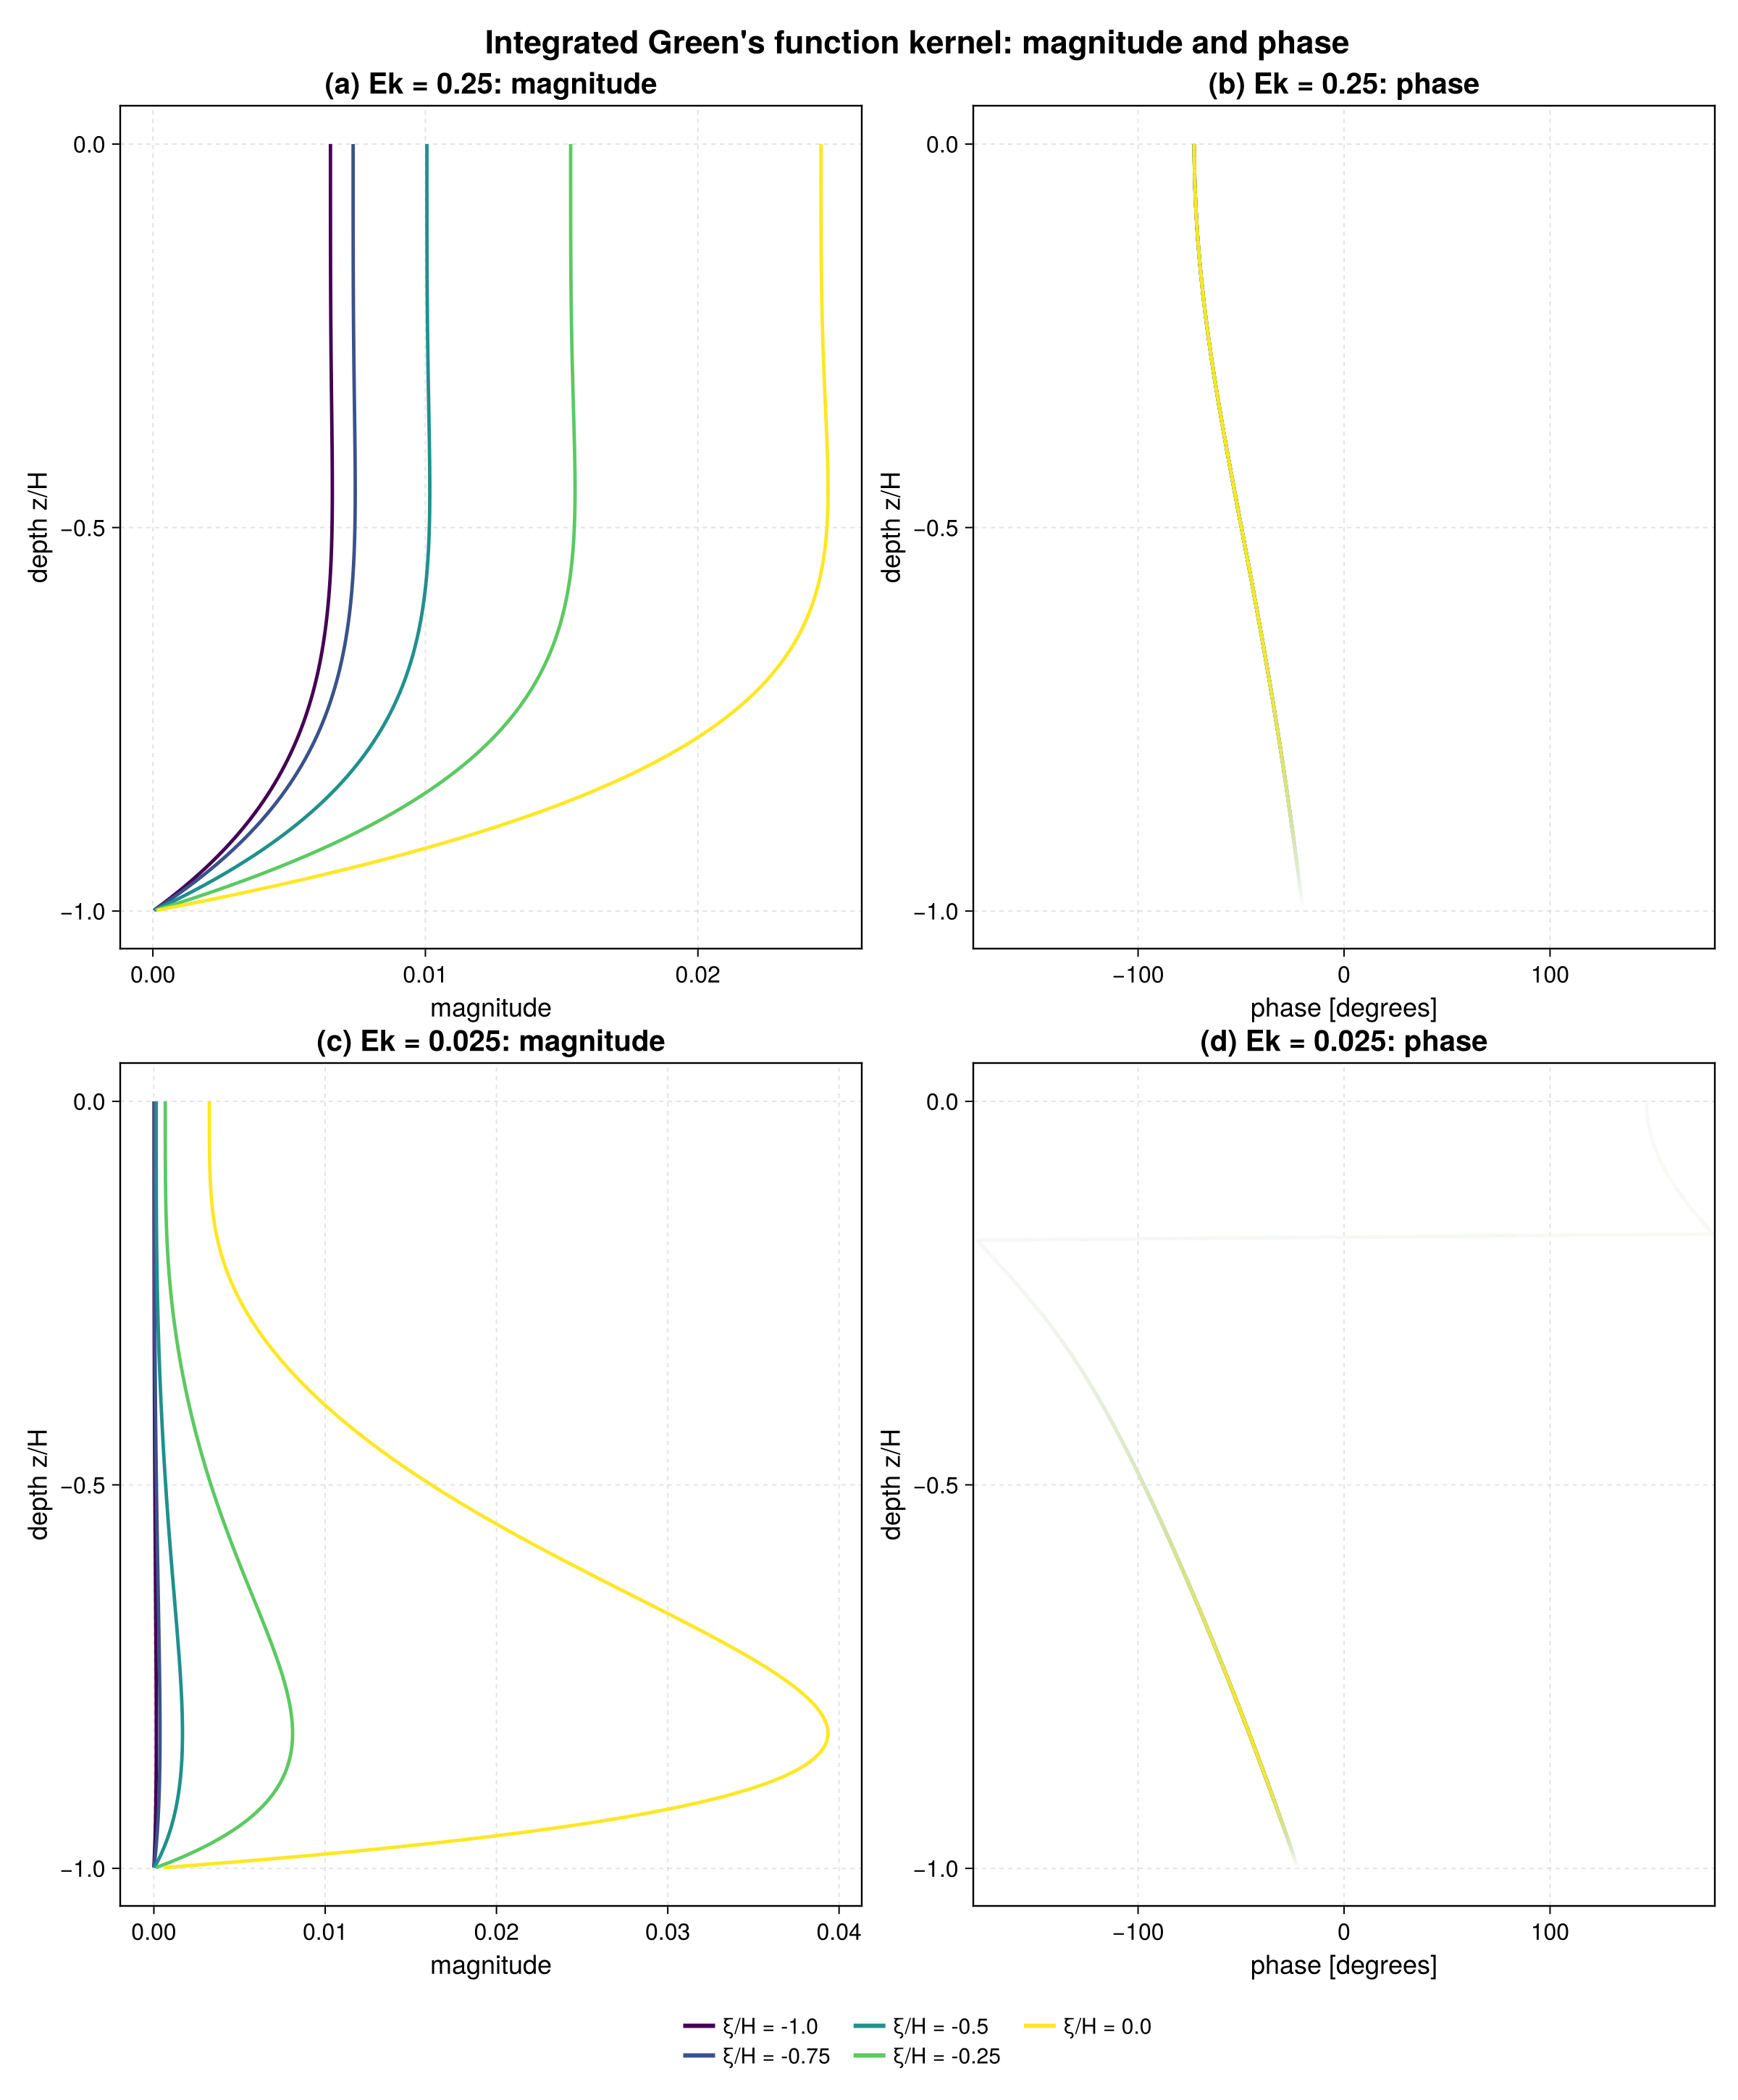

In [9]:
using CairoMakie

CairoMakie.activate!()

# -------------------------------------------------------------------
# Parameters
# -------------------------------------------------------------------
Hval = 1.0
Ek1 = 0.25
Ek2 = 0.025
Ek3 = 0.0025
# Ek_vals = [Ek1, Ek2, Ek3]
Ek_vals = [Ek1, Ek2]
varϕ_vals = [sqrt(1im / Ek) for Ek in Ek_vals]
ψ_vals = [sqrt(1 / Ek) for Ek in Ek_vals]
zgrid = range(-Hval*0.999, 0.0, length=128)   # avoids undefined phase angle at z=-H
ξp_vals = range(-Hval, 0, length=5)

# Colors for ξ families
ξcols = cgrad(:viridis, length(ξp_vals), categorical=true)

# -------------------------------------------------------------------
# Publication-style theme
# -------------------------------------------------------------------
set_theme!(
    Theme(
        fontsize=16,
        fonts=(; regular="TeX Gyre Heros"),
        Axis=(
            titlesize=20,
            xlabelsize=18,
            ylabelsize=18,
            xticklabelsize=16,
            yticklabelsize=16,
            xgridvisible=true,
            ygridvisible=true,
            xgridstyle=:dash,
            ygridstyle=:dash,
            xgridcolor=(:gray70, 0.35),
            ygridcolor=(:gray70, 0.35),
            spinewidth=1.2,
            xticksize=5,
            yticksize=5,
            xminorticksvisible=false,
            yminorticksvisible=false,
            topspinevisible=true,
            rightspinevisible=true,
        ),
        Legend=(
            framevisible=false,
            labelsize=15,
            titlesize=16,
            patchsize=(22, 14),
        ),
        Lines=(
            linewidth=2.5,
        )
    )
)

# -------------------------------------------------------------------
# Styling helper
# -------------------------------------------------------------------
function style_axis!(ax)
    ax.topspinevisible = true
    ax.rightspinevisible = true
    ax.xgridvisible = true
    ax.ygridvisible = true
    ax.xgridstyle = :dash
    ax.ygridstyle = :dash
    ax.xgridcolor = (:gray70, 0.35)
    ax.ygridcolor = (:gray70, 0.35)
    return ax
end

# Colormap that fades from white to a given color
function fade_cmap(c)
    return cgrad([RGBAf(1, 1, 1, 0.12), c])
end

# -------------------------------------------------------------------
# Figure layout
# -------------------------------------------------------------------
fig = Figure(size=(1200, 1450))

Label(fig[0, 1:2],
    "Integrated Green's function kernel: magnitude and phase",
    fontsize=22,
    font=:bold
)

# -------------------------------------------------------------------
# Helper to plot one Ek row
# -------------------------------------------------------------------
function plot_ek_row!(fig, row, Ek, varϕ, ψ; Hval=Hval, zgrid=zgrid)

    if row ==  1
        panel_labels = ("(a) ", "(b) ")
    elseif row ==2
        panel_labels = ("(c) ", "(d) ")
    elseif row == 3
        panel_labels = ("(e) ", "(f) ")
    end # if

    ax_mag = Axis(fig[row, 1],
        xlabel="magnitude",
        ylabel="depth z/H",
        title="$(panel_labels[1])Ek = $(Ek): magnitude"
    )

    ax_ph = Axis(fig[row, 2],
        xlabel="phase [degrees]",
        ylabel="depth z/H",
        title="$(panel_labels[2])Ek = $(Ek): phase"
    )

    xlims!(ax_ph, -180, 180)

     # ----------------------------------------------------------------
    # G_uvb(z; ξp) family
    # ----------------------------------------------------------------
    for (j, ξp) in enumerate(ξp_vals)
        c = ξcols[j]
        Gvals = [Guvb(Hval, z, ξp,  varϕ, ψ, 1.0, 1.0) for z in zgrid]

        mags = abs.(Gvals)
        phases = rad2deg.(angle.(Gvals))

        lines!(ax_mag, mags, zgrid,
            color=c,
            linewidth=2.4,
            label="G_u, ξ/H = $(round(ξp/Hval, digits=3))"
        )

        if isapprox(ξ, -H; atol=1e-12)
            phases = NaN .* phases
        end

        lines!(ax_ph, phases, zgrid,
            color=mags,
            colormap=fade_cmap(c),
            colorrange=(0, maximum(mags)),
            linewidth=2.4,
            label="G_u, ξ/H = $(round(ξp/Hval, digits=3))"
        )
    end

    return ax_mag, ax_ph
end

# -------------------------------------------------------------------
# Plot both Ek rows
# -------------------------------------------------------------------
ax11, ax12 = plot_ek_row!(fig, 1, Ek_vals[1], varϕ_vals[1], ψ_vals[1]; Hval=Hval)
ax21, ax22 = plot_ek_row!(fig, 2, Ek_vals[2], varϕ_vals[2], ψ_vals[2]; Hval=Hval)
# ax31, ax32 = plot_ek_row!(fig, 3, Ek_vals[3], varϕ_vals[3], ψ_vals[3]; Hval=Hval)

# Link y axes
linkyaxes!(ax11, ax21)
linkyaxes!(ax12, ax22)
# linkyaxes!(ax21, ax31)
# linkyaxes!(ax22, ax32)

# -------------------------------------------------------------------
# Single shared legend below the panels
# -------------------------------------------------------------------
legend_elements = LineElement[]
legend_labels = String[]

for (j, ξp) in enumerate(ξp_vals)
    push!(legend_elements, LineElement(color=ξcols[j], linewidth=3))
    push!(legend_labels, "ξ/H = $(round(ξp/Hval, digits=2))")
end

legend_g = Legend(fig[3, 1:2],
    legend_elements,
    legend_labels,
    title="Green's function panel",
    orientation=:horizontal,
    nbanks=2,
    framevisible=false,
    tellwidth=false,
    halign=:center
)

# -------------------------------------------------------------------
# Tightened spacing
# -------------------------------------------------------------------
colgap!(fig.layout, 1, 10)
rowgap!(fig.layout, 1, 4)
rowgap!(fig.layout, 2, 2)
# rowgap!(fig.layout, 3, 2)

# -------------------------------------------------------------------
# Save to PDF
# -------------------------------------------------------------------
CairoMakie.save("Guvb_magnitude_phase_two_Ek.pdf", fig)

fig